# 07_03 MCMC: The Metropolis Algorithm

**Learning objectives**
- Explain why we need **Markov chain Monte Carlo (MCMC)**: posteriors without a formula, and no need for the normalising constant.
- Write and run the **random-walk Metropolis** algorithm, and justify it with **detailed balance**.
- Tune the **step size** (acceptance rate about 20 to 40 %) and read the diagnostics: **trace plots, burn-in, autocorrelation, effective sample size (ESS), $\hat R$**.
- Apply it to a two-parameter Normal model and a **logistic regression**, and check against exact grid computations.

**Prerequisites:** [07_01 Bayesian updating](07_01_bayesian_updating_conjugates.ipynb), [07_02 Credible intervals](07_02_credible_intervals_predictive.ipynb), [05_04 Bootstrap and Monte Carlo](../../module_05_sampling/notebooks/05_04_bootstrap_monte_carlo.ipynb), [03_01 Multivariate normal](../../module_03_multivariate/notebooks/03_01_multivariate_normal.ipynb) (correlation).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
- The posterior is $p(\theta\mid x)\propto p(x\mid\theta)p(\theta)$ (07_01). With one or two parameters and a conjugate prior it has a formula; in general it does not, and the **normalising constant** $p(x)=\int p(x\mid\theta)p(\theta)d\theta$ is a hard integral.
- **Monte Carlo** (05_04): averages over samples approximate expectations, with error $\sigma/\sqrt N$ for independent samples.

## 3. Intuition and story
Imagine the posterior as a hilly landscape whose height is the (unnormalised) posterior density, and a hiker who wants to spend time at each place in proportion to its height. The hiker proposes a random step. If the new place is **higher**, they go there; if it is **lower**, they go with probability equal to the ratio of heights, otherwise they stay. After a while the hiker's path covers the landscape in the right proportions, so a histogram of the visited places *is* the posterior, and we never needed the total volume of the mountain.

The price: consecutive steps are correlated, the first steps depend on the starting point (burn-in), and a badly sized step makes the hiker either stuck (steps too big get rejected) or crawling (steps too small).

## 4. Formal definitions

Let $\pi(\theta)\propto p(x\mid\theta)p(\theta)$ be the target (known up to a constant). **Random-walk Metropolis:**

1. Start at $\theta^{(0)}$.
2. Propose $\theta^*=\theta^{(t)}+\varepsilon$, $\varepsilon\sim N(0,s^2I)$ (symmetric proposal).
3. Accept with probability $\alpha=\min\!\big(1,\ \pi(\theta^*)/\pi(\theta^{(t)})\big)$: set $\theta^{(t+1)}=\theta^*$; otherwise $\theta^{(t+1)}=\theta^{(t)}$.

In practice work with logs: accept if $\log u<\log\pi(\theta^*)-\log\pi(\theta^{(t)})$, $u\sim U(0,1)$.

| Diagnostic | Definition |
|---|---|
| **Acceptance rate** | share of proposals accepted; aim at 0.2 to 0.4 for a few parameters (about 0.44 in 1D, 0.23 for many) |
| **Burn-in** | the first iterations discarded because the chain has not yet reached the target |
| **Autocorrelation** | $\rho_k=\mathrm{Corr}(\theta^{(t)},\theta^{(t+k)})$ |
| **Effective sample size** | $\mathrm{ESS}=N\big/\big(1+2\sum_{k\ge1}\rho_k\big)$: the number of independent draws worth of information |
| **$\hat R$ (Gelman-Rubin)** | $\sqrt{\hat V/W}$ from several chains: within-chain variance $W$ and between-chain variance $B$, $\hat V=\frac{n-1}nW+\frac Bn$; values above about 1.01 signal non-convergence |

## 5. Derivations

### 5.1 Why the Metropolis rule has $\pi$ as its stationary distribution (detailed balance)
For two states $a\ne b$ with symmetric proposal $q(a\to b)=q(b\to a)$, the transition probability is $P(a\to b)=q(a\to b)\min(1,\pi(b)/\pi(a))$. Then
$$\pi(a)P(a\to b)=q\,\min(\pi(a),\pi(b))=\pi(b)P(b\to a).$$
This is **detailed balance**: probability flows from $a$ to $b$ as often as from $b$ to $a$ in equilibrium. Summing over $a$ gives $\sum_a\pi(a)P(a\to b)=\pi(b)$: $\pi$ is stationary. **In plain words.** The acceptance rule is built so that the long-run traffic between any two places is balanced exactly by their heights.

### 5.2 The constant cancels
$\pi(\theta^*)/\pi(\theta)=\dfrac{p(x\mid\theta^*)p(\theta^*)}{p(x\mid\theta)p(\theta)}$ because $p(x)$ appears in both. **In plain words.** The integral that blocks an exact solution is never evaluated.

### 5.3 Effective sample size
The variance of the mean of a stationary chain is $\frac{\sigma^2}{N}\big(1+2\sum_{k\ge1}\rho_k\big)$, so a chain of $N$ correlated draws has the precision of $\mathrm{ESS}=N/(1+2\sum\rho_k)$ independent ones. **In plain words.** Ten thousand draws that are strongly correlated may be worth only a hundred independent ones.

### 5.4 Choosing the step size
Too small: acceptance near 1 but the chain moves slowly (high autocorrelation). Too large: almost every proposal is rejected and the chain sits still. For a Gaussian target in $d$ dimensions the efficiency is best at $s\approx2.38\,\sigma/\sqrt d$ with acceptance about 0.23 (Roberts, Gelman and Gilks). **In plain words.** Take steps about as large as the target is wide, shrunk by $\sqrt d$ as the dimension grows.

## 6. Properties and relationships
- **Generalisations:** Metropolis-Hastings (asymmetric proposals), **Gibbs sampling** (sample each parameter from its conditional), **Hamiltonian Monte Carlo / NUTS** (uses the gradient of $\log\pi$; the default in Stan and PyMC), **simulated annealing** (optimisation).
- **Correlated parameters** slow the random walk; reparametrise, or use a proposal covariance matched to the target.
- **Multimodal targets** can trap the chain; run several chains from dispersed starting points and check $\hat R$.
- **MCMC error** is not the same as posterior uncertainty: increase $N$ to shrink the former; the latter belongs to the data.
- **Link to ML and AI:** Bayesian neural networks, topic models and probabilistic programming all rely on MCMC or its variational approximations; diffusion models and Langevin sampling are close relatives.

## 7. The sampler and the diagnostics

One compact implementation used by every example: it runs several chains in parallel (vectorised over the chains) and returns the draws and the acceptance rate.

In [2]:
def metropolis(logp, x0, n_iter, scale, rng):
    x = np.array(x0, float); lp = logp(x); C, d = x.shape; out = np.empty((n_iter, C, d)); acc = 0
    for t in range(n_iter):
        prop = x + scale * rng.normal(size=x.shape); lpn = logp(prop); ok = np.log(rng.random(C)) < lpn - lp
        x = np.where(ok[:, None], prop, x); lp = np.where(ok, lpn, lp); out[t] = x; acc += ok.mean()
    return out, acc / n_iter
def acf(x, kmax=200):
    x = x - x.mean(); f = np.fft.rfft(x, 2 * len(x)); a = np.fft.irfft(f * np.conj(f))[:len(x)]; return (a / a[0])[:kmax]
def ess_1d(x):
    r = acf(x, min(len(x) // 2, 2000)); s = 0.0
    for k in range(1, len(r) - 1, 2):
        pair = r[k] + r[k + 1]
        if pair < 0: break
        s += pair
    return len(x) / (1 + 2 * s)
def ess(chains):                                                   # chains: (n, C) for one parameter
    return sum(ess_1d(chains[:, c]) for c in range(chains.shape[1]))
def rhat(chains):
    n, C = chains.shape; W = chains.var(axis=0, ddof=1).mean(); B = n * chains.mean(axis=0).var(ddof=1); return np.sqrt(((n - 1) / n * W + B / n) / W)
# sanity check on a target with a known answer: standard Normal
rng = np.random.default_rng(0); chain, ar = metropolis(lambda z: -0.5 * (z ** 2).sum(axis=1), np.zeros((4, 1)), 20000, 2.4, rng)
print(f"standard Normal target: acceptance {ar:.3f}, mean {chain.mean():.3f}, SD {chain.std():.3f}, ESS {ess(chain[:, :, 0]):.0f} of 80000, R-hat {rhat(chain[:, :, 0]):.4f}")
assert abs(chain.mean()) < 0.05 and abs(chain.std() - 1) < 0.03 and 0.3 < ar < 0.5 and rhat(chain[:, :, 0]) < 1.01

standard Normal target: acceptance 0.443, mean 0.011, SD 1.000, ESS 18263 of 80000, R-hat 1.0001


## 8. 2D visuals

### 8.1 What a chain looks like: trace and histogram
A 1D Metropolis chain for the Beta(32, 188) posterior of lesson 07_01 (not using its formula, only the unnormalised density): the trace, and the histogram of the draws against the exact density.

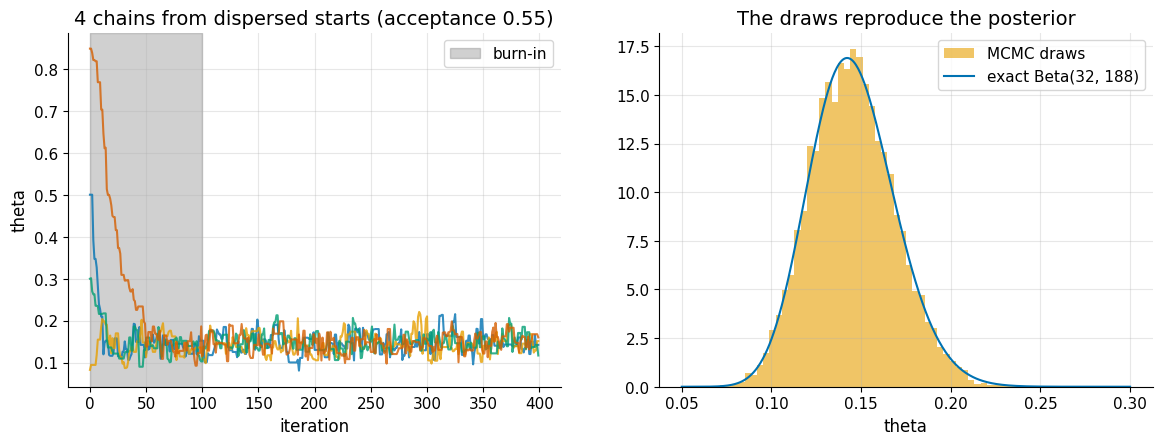

MCMC mean 0.1452 (exact 0.1455), SD 0.0235 (exact 0.0237), R-hat 1.000, ESS 4562


In [3]:
logb = lambda t: np.where((t[:, 0] > 0) & (t[:, 0] < 1), 31 * np.log(np.clip(t[:, 0], 1e-12, 1)) + 187 * np.log(np.clip(1 - t[:, 0], 1e-12, 1)), -np.inf)
ch, ar = metropolis(logb, np.array([[0.5], [0.05], [0.3], [0.9]]), 6000, 0.04, np.random.default_rng(1)); tg = np.linspace(0.05, 0.3, 400)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6)); axes[0].plot(ch[:400, :, 0], alpha=0.8); axes[0].axvspan(0, 100, color=NEUTRAL, alpha=0.3, label="burn-in"); axes[0].set_xlabel("iteration"); axes[0].set_ylabel("theta"); axes[0].set_title(f"4 chains from dispersed starts (acceptance {ar:.2f})"); axes[0].legend()
axes[1].hist(ch[500:, :, 0].ravel(), bins=60, density=True, color=SIM, alpha=0.6, label="MCMC draws"); axes[1].plot(tg, stats.beta.pdf(tg, 32, 188), color=MAIN, label="exact Beta(32, 188)"); axes[1].set_xlabel("theta"); axes[1].legend(); axes[1].set_title("The draws reproduce the posterior")
plt.show()
d_ = ch[500:, :, 0].ravel(); print(f"MCMC mean {d_.mean():.4f} (exact {32 / 220:.4f}), SD {d_.std():.4f} (exact {stats.beta.std(32, 188):.4f}), R-hat {rhat(ch[500:, :, 0]):.3f}, ESS {ess(ch[500:, :, 0]):.0f}")
assert abs(d_.mean() - 32 / 220) < 0.002 and abs(d_.std() - stats.beta.std(32, 188)) < 0.002 and rhat(ch[500:, :, 0]) < 1.02

### 8.2 Step size: too small, too large, just right
The same target (standard Normal) with step sizes 0.05, 0.5, 2.4 and 50: the traces and autocorrelations tell the story.

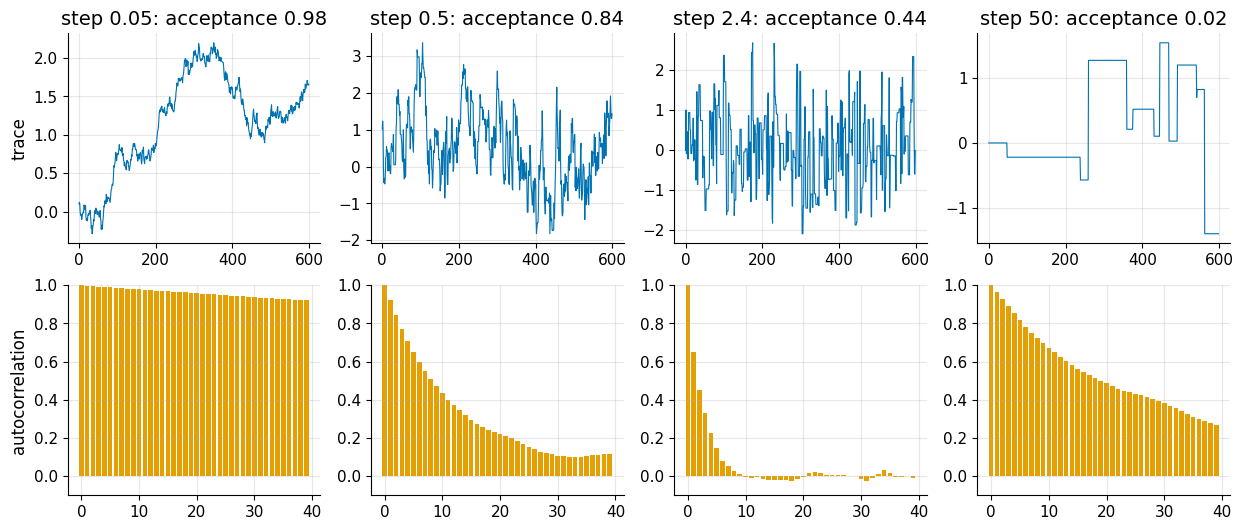

step, acceptance, ESS of 3000: [(0.05, np.float64(0.981), 4), (0.5, np.float64(0.837), 79), (2.4, np.float64(0.441), 608), (50, np.float64(0.024), 61)]


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6)); rows = []
for j, sc in enumerate([0.05, 0.5, 2.4, 50]):
    c1, a1 = metropolis(lambda z: -0.5 * (z ** 2).sum(axis=1), np.zeros((1, 1)), 3000, sc, np.random.default_rng(3)); axes[0, j].plot(c1[:600, 0, 0], color=MAIN, linewidth=0.8); axes[0, j].set_title(f"step {sc}: acceptance {a1:.2f}"); axes[1, j].bar(range(40), acf(c1[:, 0, 0], 40), color=SIM)
    axes[1, j].set_ylim(-0.1, 1); rows.append((sc, a1, ess_1d(c1[:, 0, 0])))
axes[0, 0].set_ylabel("trace"); axes[1, 0].set_ylabel("autocorrelation"); plt.show()
print("step, acceptance, ESS of 3000:", [(s, round(a, 3), round(e)) for s, a, e in rows]); assert rows[2][2] > 3 * rows[0][2] and rows[2][2] > 3 * rows[3][2]

### 8.3 Efficiency against the step size
Effective sample size per 1,000 draws for a range of step sizes, with the acceptance rate on the second axis.

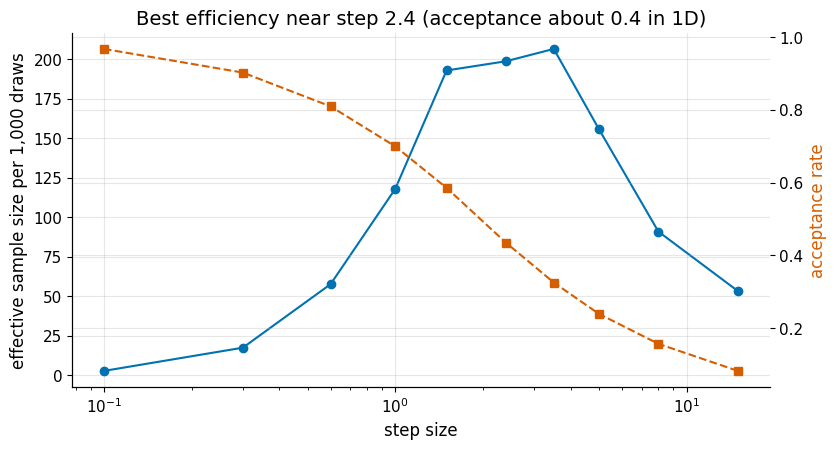

best step: 3.5


In [5]:
scs = np.array([0.1, 0.3, 0.6, 1.0, 1.5, 2.4, 3.5, 5, 8, 15]); es, ac = [], []
for sc in scs:
    c1, a1 = metropolis(lambda z: -0.5 * (z ** 2).sum(axis=1), np.zeros((4, 1)), 4000, sc, np.random.default_rng(4)); es.append(ess(c1[:, :, 0]) / 16 * 1.0); ac.append(a1)
fig, ax = plt.subplots(figsize=(9, 4.6)); ax.plot(scs, es, "o-", color=MAIN); ax.set_xscale("log"); ax.set_xlabel("step size"); ax.set_ylabel("effective sample size per 1,000 draws"); ax2 = ax.twinx(); ax2.plot(scs, ac, "s--", color=HIGHLIGHT); ax2.set_ylabel("acceptance rate", color=HIGHLIGHT); ax.set_title("Best efficiency near step 2.4 (acceptance about 0.4 in 1D)")
plt.show(); print("best step:", scs[int(np.argmax(es))])
assert scs[int(np.argmax(es))] in (1.5, 2.4, 3.5)

## 9. 3D visuals

### 9.1 Static: a chain walking over the posterior surface
The posterior of the mean and standard deviation of 25 readings (Example 1 below), drawn as a surface; the first 150 accepted-or-stayed steps of one chain are drawn on the surface.

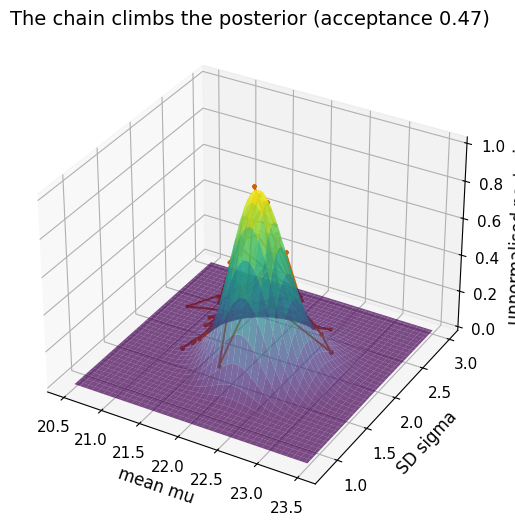

In [6]:
data = np.random.default_rng(21).normal(22, 1.5, 25); nd, xb_, S_ = data.size, data.mean(), ((data - data.mean()) ** 2).sum()
def logpost(z):                                                                    # z[:, 0] = mu, z[:, 1] = sigma ; priors: mu ~ N(20, 5^2), sigma ~ HalfNormal(3)
    mu, sg = z[:, 0], z[:, 1]; ok = sg > 0; sg_ = np.where(ok, sg, 1.0); lp = -nd * np.log(sg_) - (S_ + nd * (mu - xb_) ** 2) / (2 * sg_ ** 2) - (mu - 20) ** 2 / (2 * 25) - sg_ ** 2 / (2 * 9); return np.where(ok, lp, -np.inf)
mg = np.linspace(20.5, 23.5, 80); sgg = np.linspace(0.8, 3.0, 80); Mg, Sg = np.meshgrid(mg, sgg); LP = logpost(np.column_stack([Mg.ravel(), Sg.ravel()])).reshape(Mg.shape); PD = np.exp(LP - LP.max())
chs, ar1 = metropolis(logpost, np.array([[21.0, 2.5]]), 3000, 0.35, np.random.default_rng(5)); path = chs[:150, 0, :]; zp = np.exp(logpost(path) - LP.max())
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Mg, Sg, PD, cmap="viridis", alpha=0.7, edgecolor="none"); ax.plot(path[:, 0], path[:, 1], zp + 0.02, color=HIGHLIGHT, linewidth=1.4, marker="o", markersize=2)
ax.set_xlabel("mean mu"); ax.set_ylabel("SD sigma"); ax.set_zlabel("unnormalised posterior"); ax.set_title(f"The chain climbs the posterior (acceptance {ar1:.2f})"); ax.view_init(elev=32, azim=-60)
plt.show()

### 9.2 Interactive Plotly version of 9.1
Rotate, and see the path.

In [7]:
fig = go.Figure([go.Surface(x=mg, y=sgg, z=PD, colorscale="Viridis", opacity=0.8), go.Scatter3d(x=path[:, 0], y=path[:, 1], z=zp + 0.02, mode="lines+markers", line=dict(color="red", width=4), marker=dict(size=2))])
fig.update_layout(title="Posterior of (mu, sigma) and a Metropolis path", width=760, height=560, scene=dict(xaxis_title="mu", yaxis_title="sigma", zaxis_title="density")); fig.show()

### 9.3 Static: acceptance rate over (step size, dimension)
For a standard Normal target in $d$ dimensions: the same step size is accepted far less often as the dimension grows, which is why the step must shrink like $1/\sqrt d$.

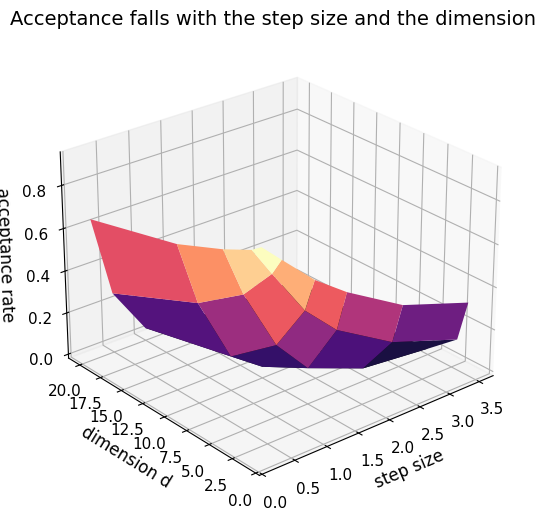

[[0.93 0.85 0.7  0.6  0.44 0.33]
 [0.9  0.76 0.55 0.4  0.24 0.13]
 [0.84 0.6  0.32 0.15 0.04 0.01]
 [0.75 0.45 0.14 0.03 0.   0.  ]
 [0.65 0.27 0.04 0.   0.   0.  ]]


In [8]:
dims = np.array([1, 2, 5, 10, 20]); stp = np.array([0.2, 0.5, 1.0, 1.5, 2.4, 3.5]); AR = np.zeros((dims.size, stp.size))
for i, d_ in enumerate(dims):
    for j, sc in enumerate(stp): AR[i, j] = metropolis(lambda z: -0.5 * (z ** 2).sum(axis=1), np.random.default_rng(0).normal(size=(4, d_)), 2000, sc, np.random.default_rng(i * 10 + j))[1]
Sx, Dx = np.meshgrid(stp, dims); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Sx, Dx, AR, cmap="magma", edgecolor="none"); ax.set_xlabel("step size"); ax.set_ylabel("dimension d"); ax.set_zlabel("acceptance rate"); ax.set_title("Acceptance falls with the step size and the dimension"); ax.view_init(elev=26, azim=-130)
plt.show(); print(np.round(AR, 2)); assert AR[0, 4] > 0.3 and AR[-1, 4] < 0.1 and AR[-1, 0] > 0.5 and AR[-1, 0] > AR[0, 0] - 0.5

## 10. Simulation vs theory

### 10.1 Does the chain have the right distribution? A goodness-of-fit check
Run the 1D chain of 8.1 for a long time and compare the empirical CDF with the exact Beta CDF using thinned draws (every 20th, to reduce the autocorrelation): the Kolmogorov-Smirnov distance should be small.

In [9]:
ch2, _ = metropolis(logb, np.full((1, 1), 0.15), 200_000, 0.04, np.random.default_rng(8)); th_ = ch2[1000::20, 0, 0]; ks = stats.kstest(th_, stats.beta(32, 188).cdf)
print(f"{th_.size} thinned draws: KS statistic {ks.statistic:.4f}, p = {ks.pvalue:.3f}; ESS of the full chain {ess_1d(ch2[1000:, 0, 0]):.0f} of {ch2.shape[0] - 1000}")
assert ks.pvalue > 0.01

9950 thinned draws: KS statistic 0.0106, p = 0.211; ESS of the full chain 40658 of 199000


### 10.2 Monte Carlo error shrinks like $1/\sqrt{\text{ESS}}$
The standard error of the posterior mean computed from the chain, against the spread of the mean over 200 independent runs.

In [10]:
means, ses = [], []
for r in range(200):
    c_, _ = metropolis(logb, np.full((1, 1), 0.15), 3000, 0.04, np.random.default_rng(100 + r)); x_ = c_[200:, 0, 0]; means.append(x_.mean()); ses.append(x_.std() / np.sqrt(ess_1d(x_)))
print(f"SD of the chain mean over 200 runs: {np.std(means):.5f} | average ESS-based standard error: {np.mean(ses):.5f}"); assert abs(np.std(means) / np.mean(ses) - 1) < 0.2

SD of the chain mean over 200 runs: 0.00097 | average ESS-based standard error: 0.00102


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("accept rule (logs): np.log(rng.random(C)) < logp(prop) - logp(x)")
print("compare with exact: stats.kstest(draws, stats.beta(a, b).cdf) ->", round(ks.pvalue, 3))
print("autocorrelation by FFT: np.fft.irfft(np.abs(np.fft.rfft(x - x.mean(), 2 * n)) ** 2) ; ESS = n / (1 + 2 * sum(rho_k))")
print("R-hat: sqrt(((n - 1) / n * W + B / n) / W) with W = mean within-chain variance, B = n * variance of chain means")
print("credible interval from draws: np.quantile(draws, [0.025, 0.975]) ->", np.round(np.quantile(th_, [0.025, 0.975]), 4))
print("library routes: PyMC / Stan / emcee / NumPyro (NUTS); this lesson writes the sampler to show how it works")

accept rule (logs): np.log(rng.random(C)) < logp(prop) - logp(x)
compare with exact: stats.kstest(draws, stats.beta(a, b).cdf) -> 0.211
autocorrelation by FFT: np.fft.irfft(np.abs(np.fft.rfft(x - x.mean(), 2 * n)) ** 2) ; ESS = n / (1 + 2 * sum(rho_k))
R-hat: sqrt(((n - 1) / n * W + B / n) / W) with W = mean within-chain variance, B = n * variance of chain means
credible interval from draws: np.quantile(draws, [0.025, 0.975]) -> [0.1027 0.1938]
library routes: PyMC / Stan / emcee / NumPyro (NUTS); this lesson writes the sampler to show how it works


## 12. Real-world worked examples

---
### Example 1 (main): mean and noise of a sensor, both unknown

**Scenario.** 25 readings from a sensor (simulated with true mean 22 and SD 1.5). Both the mean $\mu$ and the noise SD $\sigma$ are unknown. Priors: $\mu\sim N(20,5^2)$, $\sigma\sim\text{Half-Normal}(3)$. There is no conjugate formula for this prior pair, but we can check the MCMC answer against a brute-force **grid** computation.

**Questions**
1. Run four Metropolis chains and report the posterior mean, SD and 95 % credible interval of $\mu$ and $\sigma$.
2. Check convergence ($\hat R$, ESS, acceptance rate).
3. Compare with the exact posterior computed on a fine grid.
4. What is the posterior probability that $\sigma>2$ (a noisy sensor)?

### 12.1 By hand
**One Metropolis step.** From $(\mu,\sigma)=(21.0,\,2.5)$ propose $(21.3,\,2.3)$. The log-density is $\log\pi=-n\log\sigma-\frac{S+n(\mu-\bar x)^2}{2\sigma^2}-\frac{(\mu-20)^2}{50}-\frac{\sigma^2}{18}$ with $n=25$, $\bar x$ and $S=\sum(x_i-\bar x)^2$ from the data; the code below evaluates both points and the acceptance probability $\min(1,e^{\Delta})$. **Reading the posterior.** With a weak prior the mean is near $\bar x$ with standard deviation about $s/\sqrt n$, and $\sigma$ near the sample SD $s$ with relative uncertainty about $1/\sqrt{2n}$.

In [12]:
print(f"data: n = {nd}, mean = {xb_:.4f}, SD = {data.std(ddof=1):.4f}")
a_, b_ = logpost(np.array([[21.0, 2.5]]))[0], logpost(np.array([[21.3, 2.3]]))[0]; print(f"one step: log pi(current) = {a_:.3f}, log pi(proposal) = {b_:.3f}, acceptance probability = {min(1, np.exp(b_ - a_)):.4f}")
rng = np.random.default_rng(42); starts = np.array([[18.0, 4.0], [26.0, 0.8], [20.0, 3.0], [24.0, 2.0]]); chains, acc = metropolis(logpost, starts, 12000, 0.35, rng); keep = chains[2000:]
mu_d, sg_d = keep[:, :, 0], keep[:, :, 1]
summ = pd.DataFrame({"mean": [mu_d.mean(), sg_d.mean()], "SD": [mu_d.std(), sg_d.std()], "2.5%": [np.quantile(mu_d, 0.025), np.quantile(sg_d, 0.025)], "97.5%": [np.quantile(mu_d, 0.975), np.quantile(sg_d, 0.975)], "R-hat": [rhat(mu_d), rhat(sg_d)], "ESS": [ess(mu_d), ess(sg_d)]}, index=["mu", "sigma"])
print(f"Q1/Q2 (acceptance {acc:.3f}, 4 chains x 10,000 draws after 2,000 burn-in):"); print(summ.round(4).to_string())
Z = np.exp(LP - LP.max()); Zn = Z / Z.sum(); mu_ex = (Zn * Mg).sum(); sg_ex = (Zn * Sg).sum(); mu_sd = np.sqrt((Zn * (Mg - mu_ex) ** 2).sum()); sg_sd = np.sqrt((Zn * (Sg - sg_ex) ** 2).sum()); p2_ex = Zn[Sg > 2].sum()
print(f"Q3 grid: mu {mu_ex:.4f} (SD {mu_sd:.4f}), sigma {sg_ex:.4f} (SD {sg_sd:.4f}) | Q4: P(sigma > 2): MCMC {np.mean(sg_d > 2):.4f}, grid {p2_ex:.4f}")

data: n = 25, mean = 22.2196, SD = 1.6944
one step: log pi(current) = -31.761, log pi(proposal) = -29.661, acceptance probability = 1.0000


Q1/Q2 (acceptance 0.480, 4 chains x 10,000 draws after 2,000 burn-in):
          mean      SD     2.5%    97.5%   R-hat        ESS
mu     22.2072  0.3554  21.5000  22.9082  1.0005  3154.9986
sigma   1.7652  0.2653   1.3338   2.3655  1.0001  4884.8940
Q3 grid: mu 22.2077 (SD 0.3565), sigma 1.7728 (SD 0.2671) | Q4: P(sigma > 2): MCMC 0.1758, grid 0.1740


### 12.2 Asserts

In [13]:
assert acc > 0.2 and acc < 0.7 and summ["R-hat"].max() < 1.02 and summ["ESS"].min() > 800
assert abs(mu_d.mean() - mu_ex) < 0.01 and abs(sg_d.mean() - sg_ex) < 0.01 and abs(mu_d.std() - mu_sd) < 0.01 and abs(sg_d.std() - sg_sd) < 0.01 and abs(np.mean(sg_d > 2) - p2_ex) < 0.01
assert abs(mu_d.mean() - xb_) < 0.1 and abs(sg_d.mean() - data.std(ddof=1)) < 0.2
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
Calibration: draw $(\mu,\sigma)$ from the prior, simulate 25 readings, run a short MCMC and check that the 90 % credible interval for $\mu$ contains the true $\mu$ about 90 % of the time (200 repetitions).

In [14]:
g = np.random.default_rng(77); hit = 0; R = 200
for _ in range(R):
    mu_t = g.normal(20, 5); sg_t = abs(g.normal(0, 3)) + 0.05; y = g.normal(mu_t, sg_t, 25); xb2, S2 = y.mean(), ((y - y.mean()) ** 2).sum()
    lp2 = lambda z, xb2=xb2, S2=S2: np.where(z[:, 1] > 0, -25 * np.log(np.where(z[:, 1] > 0, z[:, 1], 1)) - (S2 + 25 * (z[:, 0] - xb2) ** 2) / (2 * np.where(z[:, 1] > 0, z[:, 1], 1) ** 2) - (z[:, 0] - 20) ** 2 / 50 - np.where(z[:, 1] > 0, z[:, 1], 1) ** 2 / 18, -np.inf)
    c_, _ = metropolis(lp2, np.array([[xb2, y.std(ddof=1)]] * 2), 2500, 0.8 * y.std(ddof=1) / 3 + 0.05, g); d_ = c_[500:, :, 0].ravel(); hit += (np.quantile(d_, 0.05) <= mu_t <= np.quantile(d_, 0.95))
print(f"coverage of the 90% credible interval for mu: {hit / R:.3f}"); assert 0.82 < hit / R < 0.97

coverage of the 90% credible interval for mu: 0.880


### 12.4 Plots with the regions shaded

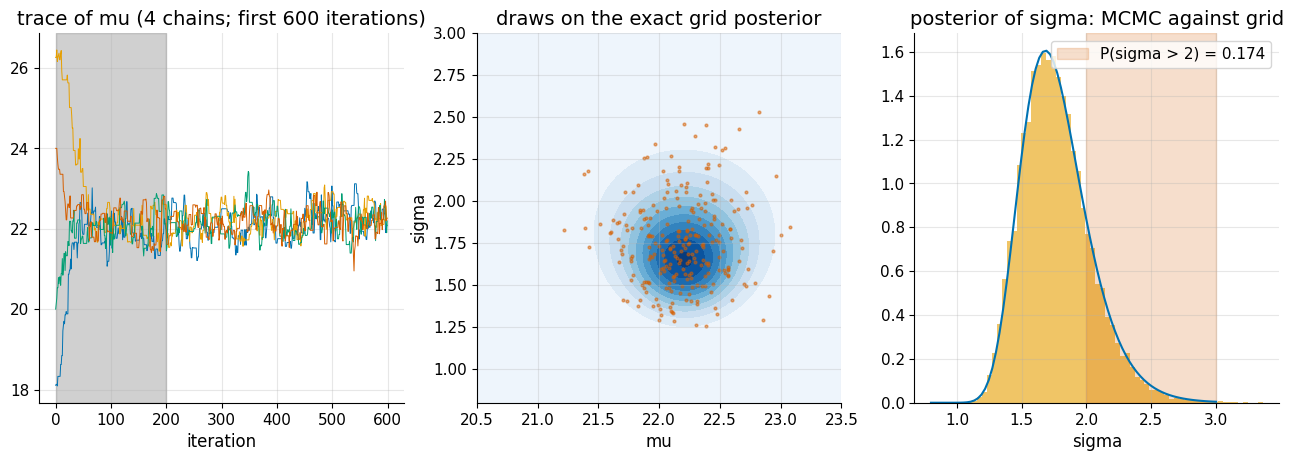

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8)); axes[0].plot(chains[:600, :, 0], linewidth=0.7); axes[0].axvspan(0, 200, color=NEUTRAL, alpha=0.3); axes[0].set_title("trace of mu (4 chains; first 600 iterations)"); axes[0].set_xlabel("iteration")
axes[1].contourf(Mg, Sg, Zn, levels=12, cmap="Blues"); axes[1].scatter(keep[::40, 0, 0], keep[::40, 0, 1], s=4, color=HIGHLIGHT, alpha=0.5); axes[1].set_xlabel("mu"); axes[1].set_ylabel("sigma"); axes[1].set_title("draws on the exact grid posterior")
axes[2].hist(sg_d.ravel(), bins=60, density=True, color=SIM, alpha=0.6); xs_ = np.linspace(0.8, 3, 200); marg = Zn.sum(axis=1) / (sgg[1] - sgg[0]); axes[2].plot(sgg, marg, color=MAIN); axes[2].axvspan(2, 3, color=HIGHLIGHT, alpha=0.2, label=f"P(sigma > 2) = {p2_ex:.3f}"); axes[2].set_xlabel("sigma"); axes[2].legend(); axes[2].set_title("posterior of sigma: MCMC against grid")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- The sample has mean 22.22 and SD 1.69. The four chains (acceptance **0.48**, started at four dispersed points) give $\mu$: mean **22.21**, SD 0.355, 95 % interval **(21.50, 22.91)**; $\sigma$: mean **1.77**, SD 0.265, 95 % interval **(1.33, 2.37)**.
- **Convergence is clean:** $\hat R=1.0005$ and $1.0001$; ESS **3,155** for $\mu$ and **4,885** for $\sigma$ out of 40,000 draws, so the Monte Carlo error is far below the posterior uncertainty.
- **The exact grid agrees:** $\mu$ 22.208 (SD 0.357), $\sigma$ 1.773 (SD 0.267); $P(\sigma>2)$ is **0.176** by MCMC against 0.174 on the grid. The calibration test (draw the truth from the prior, repeat 200 times) gives a coverage of **88 %** for a nominal 90 % interval, within sampling noise.
- **Decision.** The sensor reads about 22.2 with an uncertainty of 0.36 and a noise SD of about 1.8; there is an 18 % chance that its noise exceeds 2 degrees. For a specification of "noise below 2", collect more readings before accepting the sensor.

---
### Example 2: how price affects purchases (Bayesian logistic regression)

**Scenario.** 300 visitors saw a product at different prices. The standardised price $z$ (mean 0, SD 1) and the purchase indicator $y$ are recorded; the true model is $P(\text{buy})=\mathrm{logistic}(-0.4-0.9z)$. Priors: $\beta_0,\beta_1\sim N(0,2.5^2)$.

**Questions**
1. Sample the posterior of $(\beta_0,\beta_1)$ and give 95 % intervals.
2. What is the odds ratio for a price one SD higher, and $P(\beta_1<0)$?
3. What is the posterior predictive probability of a purchase at $z=+1$ with its 95 % interval?

In [16]:
g = np.random.default_rng(2); zp_ = g.normal(size=300); yp_ = (g.random(300) < 1 / (1 + np.exp(0.4 + 0.9 * zp_))).astype(float)
def lp_logit(b):
    eta = b[:, [0]] + b[:, [1]] * zp_[None, :]; return (yp_ * eta - np.logaddexp(0, eta)).sum(axis=1) - (b ** 2).sum(axis=1) / (2 * 2.5 ** 2)
ch3, ac3 = metropolis(lp_logit, g.normal(0, 2, size=(4, 2)), 12000, 0.2, g); k3 = ch3[2000:]; b0d, b1d = k3[:, :, 0], k3[:, :, 1]
from scipy.optimize import minimize
mle = minimize(lambda b: -lp_logit(b[None, :])[0], [0, 0]).x
print(f"acceptance {ac3:.3f} | R-hat: {rhat(b0d):.3f}, {rhat(b1d):.3f} | ESS: {ess(b0d):.0f}, {ess(b1d):.0f}")
print(f"Q1: beta0 mean {b0d.mean():.3f}, 95% {np.round(np.quantile(b0d, [0.025, 0.975]), 3)} | beta1 mean {b1d.mean():.3f}, 95% {np.round(np.quantile(b1d, [0.025, 0.975]), 3)} | MAP (prior included) {np.round(mle, 3)}")
orr = np.exp(b1d.ravel()); print(f"Q2: odds ratio per +1 SD price: median {np.median(orr):.3f}, 95% interval {np.round(np.quantile(orr, [0.025, 0.975]), 3)}, P(beta1 < 0) = {np.mean(b1d < 0):.4f}")
pz1 = 1 / (1 + np.exp(-(b0d.ravel() + b1d.ravel()))); print(f"Q3: P(buy | z = +1): mean {pz1.mean():.3f}, 95% interval {np.round(np.quantile(pz1, [0.025, 0.975]), 3)} (truth {1 / (1 + np.exp(1.3)):.3f})")
assert rhat(b0d) < 1.02 and rhat(b1d) < 1.02 and ess(b1d) > 500 and b1d.mean() < -0.4 and np.mean(b1d < 0) > 0.999 and np.quantile(b1d, 0.025) < -0.9 < np.quantile(b1d, 0.975) and abs(b1d.mean() - mle[1]) < 0.06

acceptance 0.388 | R-hat: 1.001, 1.000 | ESS: 5275, 4620
Q1: beta0 mean -0.414, 95% [-0.667 -0.172] | beta1 mean -0.785, 95% [-1.059 -0.525] | MAP (prior included) [-0.409 -0.773]
Q2: odds ratio per +1 SD price: median 0.457, 95% interval [0.347 0.592], P(beta1 < 0) = 1.0000
Q3: P(buy | z = +1): mean 0.234, 95% interval [0.166 0.307] (truth 0.214)


### 12.6 Simulation and plot
The posterior mode agrees with the optimiser's MAP; the predicted purchase curve with its credible band:

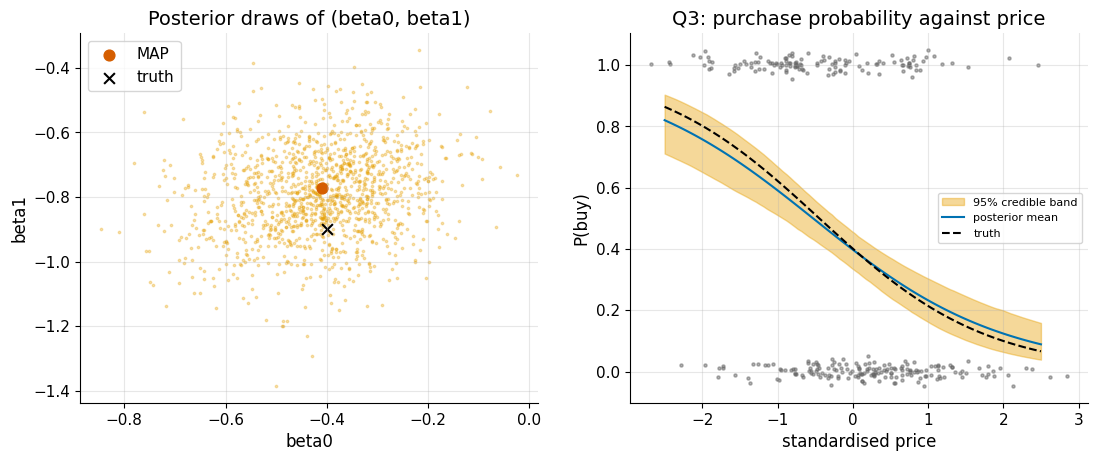

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].scatter(b0d.ravel()[::30], b1d.ravel()[::30], s=3, alpha=0.3, color=SIM); axes[0].scatter(*mle, color=HIGHLIGHT, s=60, label="MAP"); axes[0].scatter(-0.4, -0.9, color="black", marker="x", s=60, label="truth"); axes[0].set_xlabel("beta0"); axes[0].set_ylabel("beta1"); axes[0].legend(); axes[0].set_title("Posterior draws of (beta0, beta1)")
zg = np.linspace(-2.5, 2.5, 100); P = 1 / (1 + np.exp(-(b0d.ravel()[::20, None] + b1d.ravel()[::20, None] * zg))); axes[1].fill_between(zg, np.quantile(P, 0.025, axis=0), np.quantile(P, 0.975, axis=0), color=SIM, alpha=0.4, label="95% credible band"); axes[1].plot(zg, P.mean(axis=0), color=MAIN, label="posterior mean"); axes[1].plot(zg, 1 / (1 + np.exp(0.4 + 0.9 * zg)), color="black", linestyle="--", label="truth"); axes[1].scatter(zp_, yp_ + 0.02 * g.normal(size=300), s=5, color=NEUTRAL, alpha=0.5); axes[1].set_xlabel("standardised price"); axes[1].set_ylabel("P(buy)"); axes[1].legend(fontsize=8); axes[1].set_title("Q3: purchase probability against price")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The chains mix well (acceptance **0.39**, $\hat R\le1.001$, ESS about 5,000 of 40,000). The posterior of the intercept is **$-0.41$** with 95 % interval $(-0.67,\,-0.17)$ and of the price slope **$-0.79$** with interval $(-1.06,\,-0.53)$; both contain the true values ($-0.4$ and $-0.9$), and the posterior mean of the slope matches the optimiser's MAP ($-0.77$).
- A price one SD higher multiplies the odds of buying by **0.46** (95 % interval 0.35 to 0.59); $P(\beta_1<0)\approx1$. At $z=+1$ the purchase probability is **0.234** (95 % interval 0.166 to 0.307; truth 0.214): the posterior predictive probability comes with an honest interval for free, which a point estimate does not give.
- **Decision.** Raising the price by one SD lowers purchases from about 40 % to 23 %; compute revenue per visitor from the whole posterior (not only its mean) when choosing the price.

---
### Example 3: when MCMC goes wrong (correlated parameters and diagnostics)

**Scenario.** Two highly correlated parameters (correlation 0.95), a target that real models often produce. Compare random-walk step sizes and see what the diagnostics say.

**Questions.** (1) For step sizes 0.05, 0.3, 1 and 10, report the acceptance rate, ESS and $\hat R$. (2) Why is the best step smaller than in one dimension? (3) What happens on a **bimodal** target when the step is small?

       acceptance  ESS of x (of 20,000)  R-hat of x  mean of x  corr(x, y)
step                                                                      
0.05        0.924                34.500       1.113      0.713       0.915
0.30        0.605               108.915       1.009      0.068       0.957
1.00        0.232               442.481       1.001      0.096       0.953
10.00       0.006                96.039       1.019     -0.139       0.953


bimodal target (modes at -4 and +4), chains started in both: step -> (acceptance, R-hat, share of draws in the right mode; truth 0.5): {0.5: (np.float64(0.758), np.float64(4.096), np.float64(0.25)), 3.0: (np.float64(0.182), np.float64(1.009), np.float64(0.396))}


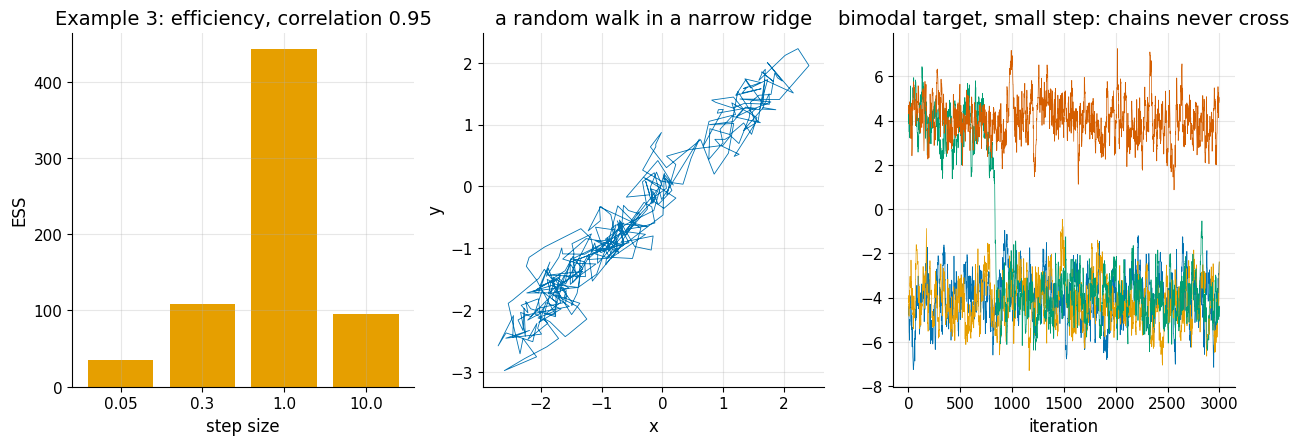

In [18]:
cov = np.array([[1, 0.95], [0.95, 1]]); icov = np.linalg.inv(cov); lp_c = lambda z: -0.5 * np.einsum("ci,ij,cj->c", z, icov, z); rows = []
for sc in [0.05, 0.3, 1.0, 10.0]:
    c_, a_ = metropolis(lp_c, np.random.default_rng(1).normal(0, 3, size=(4, 2)), 6000, sc, np.random.default_rng(9)); kk = c_[1000:]; rows.append({"step": sc, "acceptance": a_, "ESS of x (of 20,000)": ess(kk[:, :, 0]), "R-hat of x": rhat(kk[:, :, 0]), "mean of x": kk[:, :, 0].mean(), "corr(x, y)": np.corrcoef(kk[:, :, 0].ravel(), kk[:, :, 1].ravel())[0, 1]})
tab = pd.DataFrame(rows).set_index("step"); print(tab.round(3).to_string())
lp_bi = lambda z: np.logaddexp(-0.5 * ((z[:, 0] + 4) ** 2 + z[:, 1] ** 2), -0.5 * ((z[:, 0] - 4) ** 2 + z[:, 1] ** 2)); rb = {}
for sc in [0.5, 3.0]:
    c_, a_ = metropolis(lp_bi, np.array([[-4.0, 0], [-4.0, 0], [4.0, 0], [4.0, 0]]), 8000, sc, np.random.default_rng(10)); kk = c_[1000:, :, 0]; rb[sc] = (a_, rhat(kk), np.mean(kk > 0))
print("bimodal target (modes at -4 and +4), chains started in both: step -> (acceptance, R-hat, share of draws in the right mode; truth 0.5):", {k: tuple(round(v, 3) for v in t) for k, t in rb.items()})
assert tab.loc[0.3, "ESS of x (of 20,000)"] > tab.loc[0.05, "ESS of x (of 20,000)"] and tab.loc[0.3, "ESS of x (of 20,000)"] > tab.loc[10.0, "ESS of x (of 20,000)"] and rb[0.5][1] > 1.5 and rb[3.0][1] < 1.1 and abs(tab.loc[1.0, "corr(x, y)"] - 0.95) < 0.05
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6)); axes[0].bar([str(s) for s in tab.index], tab["ESS of x (of 20,000)"], color=SIM); axes[0].set_xlabel("step size"); axes[0].set_ylabel("ESS"); axes[0].set_title("Example 3: efficiency, correlation 0.95")
c_, _ = metropolis(lp_c, np.zeros((1, 2)), 600, 0.3, np.random.default_rng(2)); axes[1].plot(c_[:, 0, 0], c_[:, 0, 1], color=MAIN, linewidth=0.6); axes[1].set_title("a random walk in a narrow ridge"); axes[1].set_xlabel("x"); axes[1].set_ylabel("y")
cb, _ = metropolis(lp_bi, np.array([[-4.0, 0], [-4.0, 0], [4.0, 0], [4.0, 0]]), 3000, 0.5, np.random.default_rng(10)); axes[2].plot(cb[:, :, 0], linewidth=0.5); axes[2].set_title("bimodal target, small step: chains never cross"); axes[2].set_xlabel("iteration")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- For two parameters with correlation 0.95 a step of 0.05 is accepted 92 % of the time but the chain crawls (ESS **35** of 20,000 and $\hat R=1.11$: not converged); a step of 10 is accepted only 0.6 % of the time (ESS 96); steps of 0.3 and **1.0** do better, with the best at 1.0 (acceptance 0.23, ESS **442**) after which the chain recovers the correlation 0.95. In one dimension the best step was near 2.4 to 3.5, here it is much smaller because the target is a narrow diagonal ridge and the random walk must move along it with isotropic steps.
- On the **bimodal** target with modes at $\pm4$, a step of 0.5 gives $\hat R=4.1$: the chains stay in the mode in which they started and the share of draws in the right-hand mode (0.25) is wrong; a step of 3 crosses between the modes ($\hat R=1.009$, share 0.40, still noisy because crossings are rare).
- **Decision.** Always run several chains from dispersed starts, read $\hat R$ and ESS, and treat low ESS or $\hat R>1.01$ as a failure; for correlated or high-dimensional targets use a gradient-based sampler (HMC/NUTS) or reparametrise.

## 13. Where it is used

### Statistics
- **Bayesian inference** for any model: hierarchical and mixed models, survival models, spatial statistics, phylogenetics, cosmology; Gibbs sampling in classical latent-variable models.
- **Computing normalising constants and expectations** in statistical physics (the original use of Metropolis in 1953).

### Data science
- **Probabilistic programming** (PyMC, Stan, NumPyro): Hamiltonian Monte Carlo (NUTS) is the default sampler; posterior predictive checks and uncertainty for marketing-mix models, demand forecasting, pricing (Example 2).
- **Diagnostics** ($\hat R$, ESS, trace plots, divergences) are part of every Bayesian report.

### ML and AI
- **Bayesian neural networks and deep ensembles' uncertainty:** stochastic-gradient Langevin dynamics and HMC; **energy-based and diffusion models** sample with Langevin-type chains; **Markov random fields**, **topic models** (collapsed Gibbs sampling) and **reinforcement learning** (MCMC tree search ideas).
- **Variational inference** is the optimisation-based alternative when MCMC is too slow.

## 14. Common pitfalls and misconceptions

- **Judging convergence by eye on one chain:** use several dispersed chains, $\hat R$ and ESS.
- **Too few effective samples:** 10,000 draws may be worth 100 (Example 3); report ESS, not only $N$.
- **Starting values and burn-in:** discard the early part, but burn-in cannot rescue a chain that never found the main mass (bimodal target).
- **Step size by acceptance only:** acceptance near 1 can mean tiny steps (slow), near 0 means stuck; aim for 0.2 to 0.4.
- **Forgetting the boundaries:** return $\log\pi=-\infty$ outside the support (here $\sigma\le0$).
- **Improper or too-flat priors** can give improper posteriors that a sampler happily explores forever.
- **MCMC is not magic:** correlated or high-dimensional posteriors need gradient-based samplers or reparametrisation.

## 15. Exercises

1. Run Metropolis for the Gamma(51, 32) posterior of lesson 07_01 (error rate) with step 0.3 and compare the mean and SD with the exact values.
2. For a standard Normal target compute the acceptance rate for step sizes 0.5, 2.4 and 10 (one chain of 20,000 draws).
3. Show that discarding no burn-in barely matters when the chain starts at the mode but matters when it starts far away (start at 50 for a standard Normal target).
4. For the Beta(32, 188) target compute the ESS and the Monte Carlo standard error of the mean for a chain of 10,000 draws with step 0.04.
5. Use thinning (every 10th draw) on the same chain: what happens to the ESS? Is thinning worth it?
6. (Harder) Run the sampler of Example 2 with step sizes 0.05, 0.2 and 1.0 and compare the acceptance rate and the ESS of $\beta_1$.

Solutions are at the end.

## 16. Summary table

| Item | Rule | Note |
|---|---|---|
| Metropolis step | accept with prob $\min(1,\pi(\theta^*)/\pi(\theta))$ | normalising constant cancels |
| Stationary law | detailed balance | $\pi(a)P(a\to b)=\pi(b)P(b\to a)$ |
| Step size | about $2.4\sigma/\sqrt d$ | acceptance 0.23 to 0.44 |
| ESS | $N/(1+2\sum\rho_k)$ | information in the chain |
| $\hat R$ | between over within variance | below 1.01 |
| Failure modes | multimodality, strong correlation, bad scale | use several chains |
| tools | PyMC, Stan, NumPyro; here NumPy | |

## Solutions

In [19]:
lg = lambda z: np.where(z[:, 0] > 0, 50 * np.log(np.where(z[:, 0] > 0, z[:, 0], 1)) - 32 * z[:, 0], -np.inf); c1, a1 = metropolis(lg, np.array([[1.5]]), 40000, 0.3, np.random.default_rng(1)); x1 = c1[2000:, 0, 0]
print(f"1: acceptance {a1:.3f}, mean {x1.mean():.4f} (exact {51 / 32:.4f}), SD {x1.std():.4f} (exact {np.sqrt(51) / 32:.4f})")
print("2: acceptance for steps 0.5, 2.4, 10:", [round(metropolis(lambda z: -0.5 * (z ** 2).sum(axis=1), np.zeros((1, 1)), 20000, sc, np.random.default_rng(5))[1], 3) for sc in (0.5, 2.4, 10)])
far, _ = metropolis(lambda z: -0.5 * (z ** 2).sum(axis=1), np.full((1, 1), 50.0), 300, 2.4, np.random.default_rng(6)); near, _ = metropolis(lambda z: -0.5 * (z ** 2).sum(axis=1), np.zeros((1, 1)), 300, 2.4, np.random.default_rng(6))
print(f"3: mean of the first 300 draws: start at 50 -> {far.mean():.2f}, start at 0 -> {near.mean():.2f}; first iteration within 3 of 0 for start 50: {int(np.argmax(np.abs(far[:, 0, 0]) < 3))}")
c4, _ = metropolis(logb, np.full((1, 1), 0.15), 10000, 0.04, np.random.default_rng(7)); x4 = c4[:, 0, 0]; e4 = ess_1d(x4); print(f"4: ESS {e4:.0f} of 10000, MC standard error of the mean {x4.std() / np.sqrt(e4):.5f} (iid would be {x4.std() / 100:.5f})")
x5 = x4[::10]; print(f"5: thinned chain: {x5.size} draws, ESS {ess_1d(x5):.0f} (before: {e4:.0f}): thinning discards information and only saves storage")
r6 = []
for sc in (0.05, 0.2, 1.0):
    c6, a6 = metropolis(lp_logit, np.random.default_rng(3).normal(0, 1, size=(4, 2)), 6000, sc, np.random.default_rng(4)); r6.append((sc, round(a6, 3), round(ess(c6[1000:, :, 1]))))
print("6: (step, acceptance, ESS of beta1 out of 20,000):", r6)
assert abs(x1.mean() - 51 / 32) < 0.01 and ess_1d(x5) <= e4

1: acceptance 0.623, mean 1.5936 (exact 1.5938), SD 0.2229 (exact 0.2232)


2: acceptance for steps 0.5, 2.4, 10: [np.float64(0.85), np.float64(0.44), np.float64(0.127)]
3: mean of the first 300 draws: start at 50 -> 3.79, start at 0 -> -0.02; first iteration within 3 of 0 for start 50: 41


4: ESS 1768 of 10000, MC standard error of the mean 0.00056 (iid would be 0.00024)
5: thinned chain: 1000 draws, ESS 653 (before: 1768): thinning discards information and only saves storage


6: (step, acceptance, ESS of beta1 out of 20,000): [(0.05, np.float64(0.809), 475), (0.2, np.float64(0.393), 2376), (1.0, np.float64(0.033), 476)]


**1.** Metropolis with step 0.3 on the Gamma(51, 32) posterior: acceptance **0.62**, mean **1.5936** (exact 1.5938), SD **0.2229** (exact 0.2232).

**2.** Acceptance rates for steps 0.5, 2.4, 10: **0.85, 0.44, 0.13**.

**3.** Starting at 50 for a standard Normal target, the chain needs **41 iterations** to get within 3 of the centre; the mean of the first 300 draws is **3.79** against **$-0.02$** when starting at 0: burn-in matters when the start is far from the mass.

**4.** For the Beta(32, 188) chain with step 0.04: ESS **1,768** of 10,000; the Monte Carlo standard error of the mean is **0.00056** (an independent sample would have given 0.00024).

**5.** Thinning every 10th draw leaves 1,000 draws with ESS **653**, down from 1,768: thinning throws away information; it only saves storage.

**6.** Step 0.05: acceptance **0.81**, ESS of $\beta_1$ **475**; step 0.2: acceptance **0.39**, ESS **2,376**; step 1.0: acceptance **0.03**, ESS **476**. Both too small and too large steps lose a factor of 5 in efficiency.